# Chapter 3 — Dimensionality Reduction Techniques
**Buku:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt, 2025)
**Cakupan notebook:** reproduksi kode + ringkasan + penjelasan teori Chapter 3 (tanpa bagian *Hands-on/Practical exercises*)


## Ringkasan Chapter
Chapter 3 membahas **reduksi dimensi**: mengurangi jumlah fitur sambil mempertahankan informasi relevan. Tujuannya menyederhanakan data, menurunkan biaya komputasi, mengurangi overfitting, dan memungkinkan visualisasi. Tiga teknik utama diperkenalkan: **PCA** (unsupervised, memaksimalkan variansi), **LDA** (supervised, memaksimalkan keterpisahan kelas), dan **t-SNE** (non-linear, untuk visualisasi). Chapter ditutup dengan panduan memilih teknik dan pembahasan trade-off terhadap performa model.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.8.0


## 0. Pengantar Reduksi Dimensi
**Mengapa penting?** (*garbage in, garbage out*: lebih banyak fitur belum tentu lebih baik)
- **Menyederhanakan data:** data berdimensi tinggi sulit divisualisasi dan diinterpretasi.
- **Mengurangi biaya komputasi:** fitur lebih sedikit → pelatihan lebih cepat dan hemat sumber daya.
- **Meningkatkan performa model:** mengurangi risiko *overfitting* (model mempelajari *noise*) dengan membuang fitur redundan atau tidak relevan.
- **Memudahkan visualisasi:** data tinggi-dimensi diproyeksikan ke 2D/3D.

**Dua kategori besar:**

| Kategori | Ide | Contoh |
|---|---|---|
| **Feature selection** | Memilih subset fitur asli tanpa mengubahnya | *Filter* (korelasi dengan target), *wrapper* (RFE), *embedded* (Lasso), *hybrid* |
| **Feature extraction** | Mengubah fitur asli menjadi ruang baru berdimensi lebih rendah | PCA, LDA, t-SNE |

**Langkah umum:** (1) nilai dimensi data dan masalahnya, (2) pilih metode sesuai tujuan, (3) terapkan dengan scikit-learn, (4) latih model pada data asli vs data tereduksi lalu bandingkan metriknya.

## 1. Transforming Datasets with PCA
**PCA (Principal Component Analysis)** mentransformasi data ke sistem koordinat baru di mana variansi terbesar ditangkap oleh dimensi pertama (*principal component*, PC). Cocok untuk menyederhanakan dataset berdimensi tinggi.

### Getting ready: dataset Wine
178 sampel, 13 fitur kimia, 3 kelas anggur. Fitur harus **distandarisasi** sebelum PCA, dan variabel target harus **dipisah** agar tidak ikut dalam PCA.

In [ ]:
# [Dari buku] Muat dataset Wine
from sklearn.datasets import load_wine

np.random.seed(2024)   # reproducibility
warnings.simplefilter(action="ignore", category=FutureWarning)

wine = load_wine()
df_wine = pd.DataFrame(data=wine.data, columns=wine.feature_names)
target_wine = wine.target
display(df_wine.head(10))
print("Bentuk:", df_wine.shape, "| Kelas:", [str(n) for n in wine.target_names])

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


Bentuk: (178, 13) | Kelas: ['class_0', 'class_1', 'class_2']


### How to do it…
Buku memakai `Pipeline` untuk merangkai `StandardScaler` → `PCA(n_components=2)`. Pola ini akan sering muncul di sisa buku.

In [ ]:
# [Dari buku] Pipeline PCA: scaling -> PCA 2 komponen
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),     # selalu scaling sebelum PCA
    ("pca", PCA(n_components=2)),     # reduksi ke 2 dimensi
])
X_pca = pca_pipeline.fit_transform(df_wine)
print("Bentuk sebelum:", df_wine.shape, "-> sesudah:", X_pca.shape)

Bentuk sebelum: (178, 13) -> sesudah: (178, 2)


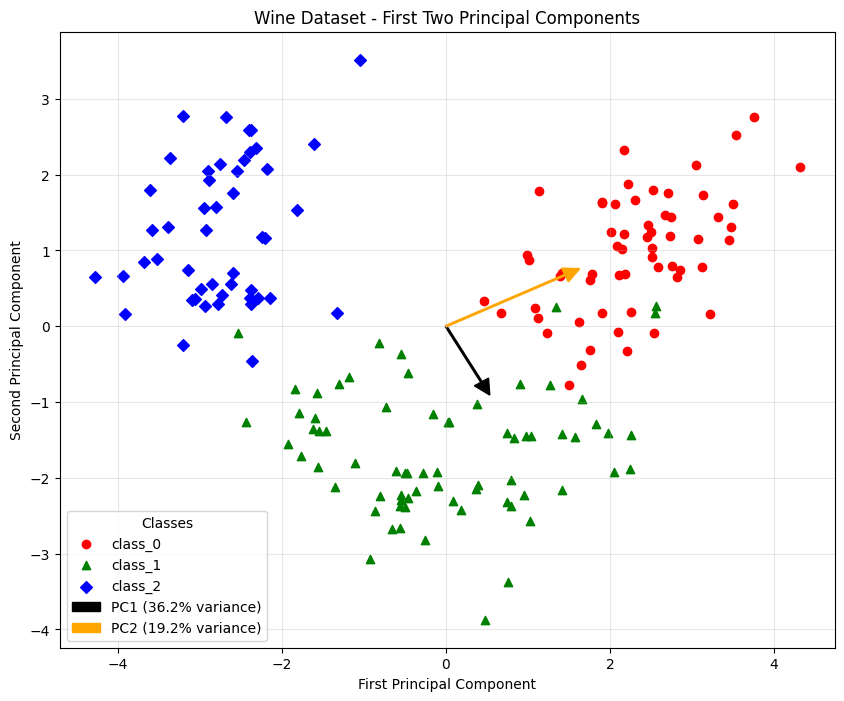

In [ ]:
# [Dari buku] Scatter plot hasil PCA + vektor arah komponen
# Catatan: buku menulis plt.legend(title=“Classes”) dengan tanda kutip melengkung (SyntaxError); di sini diperbaiki.
plt.figure(figsize=(10, 8))
shapes = ["o", "^", "D"]
colors = ["r", "g", "b"]

for i, (shape, color) in enumerate(zip(shapes, colors)):
    plt.scatter(
        X_pca[target_wine == i, 0], X_pca[target_wine == i, 1],
        c=color, marker=shape, label=wine.target_names[i],
    )

pca = pca_pipeline.named_steps["pca"]
origin = np.zeros(2)
arrow_colors = ["black", "orange"]
scaling = 3   # skala panah agar terlihat

for i, (component, ratio) in enumerate(zip(pca.components_, pca.explained_variance_ratio_)):
    plt.arrow(
        origin[0], origin[1], component[0] * scaling, component[1] * scaling,
        color=arrow_colors[i], width=0.02, head_width=0.2, head_length=0.2,
        label=f"PC{i+1} ({ratio:.1%} variance)",
    )

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("Wine Dataset - First Two Principal Components")
plt.legend(title="Classes")
plt.grid(True, alpha=0.3)
plt.show()

**Interpretasi:** setiap titik adalah satu anggur, diposisikan berdasarkan dua komponen utama hasil kompresi 13 fitur. Tiga kelas terlihat sudah cukup terpisah walaupun PCA **tidak memakai label kelas**. Legenda panah menunjukkan persentase variansi tiap komponen (PC1 36,2%, PC2 19,2%).

> **Catatan penting tentang panah:** kode buku menggambar panah dari dua angka pertama tiap vektor `components_`, yaitu bobot (*loading*) fitur `alcohol` dan `malic_acid` pada PC1 dan PC2. Pada plot ini sumbu-x sudah PC1 dan sumbu-y sudah PC2, jadi panah itu **bukan** arah sumbu komponen. Jangan dibaca sebagai "arah PC1/PC2" seperti yang tersirat di teks buku. Arah komponen yang benar ditunjukkan pada gambar Figure 3.4 versi saya di bawah (panah digambar di ruang fitur asli).

### How it works…
PCA mencari arah (*principal component*) di mana data paling bervariasi. Komponen adalah **kombinasi linear** fitur asli dan saling **ortogonal** (tegak lurus). Langkah-langkahnya:
1. **Standardisasi** (mean 0, variansi 1), karena PCA sensitif terhadap skala variansi.
2. **Matriks kovarians:** menangkap seberapa besar dimensi-dimensi bervariasi bersama.
3. **Eigenvalue dan eigenvector:** eigenvalue = jumlah variansi yang ditangkap sebuah komponen, eigenvector = arah komponen.
4. **Memilih komponen:** ambil beberapa komponen dengan eigenvalue terbesar.
5. **Transformasi:** proyeksikan data asli ke komponen terpilih.

Secara matematis, jika $\Sigma$ adalah matriks kovarians data terstandarisasi, PCA mencari $\Sigma v = \lambda v$; rasio variansi komponen ke-$k$ adalah $\lambda_k / \sum_j \lambda_j$.

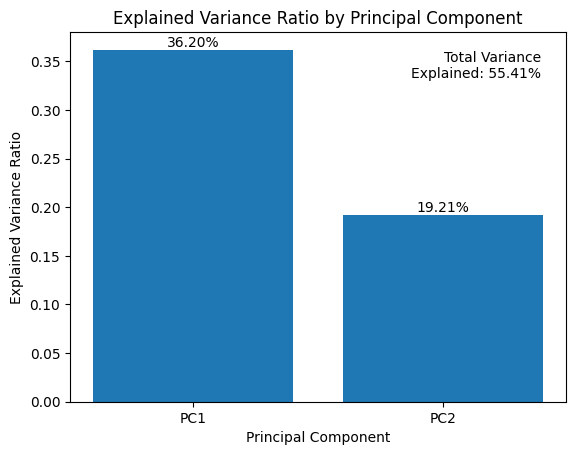

In [ ]:
# [Dari buku] Bar chart explained variance ratio
pca = pca_pipeline.named_steps["pca"]
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.sum(explained_variance_ratio)

fig, ax = plt.subplots()
x = np.arange(1, len(explained_variance_ratio) + 1)
y = explained_variance_ratio
bars = ax.bar(x, y)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2., height, f"{height:.2%}", ha="center", va="bottom")

ax.text(
    0.95, 0.95, f"Total Variance\nExplained: {cumulative_variance:.2%}",
    transform=ax.transAxes, ha="right", va="top",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
)
ax.set_xticks(x)
ax.set_xticklabels(["PC1", "PC2"])
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance Ratio")
ax.set_title("Explained Variance Ratio by Principal Component")
plt.show()

**Interpretasi:** dua komponen pertama bersama-sama menjelaskan **55,41%** total variansi (di buku: Figure 3.3, nilai yang sama). Artinya kita memampatkan 13 fitur menjadi 2 dimensi dengan mempertahankan sedikit lebih dari separuh informasi (variansi) data.

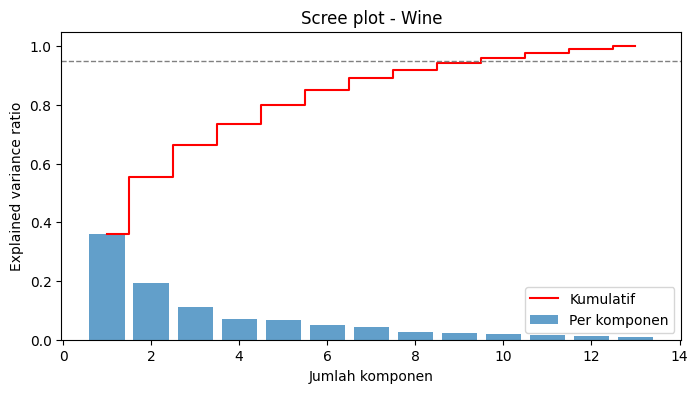

Komponen untuk >= 80% variansi: 5
Komponen untuk >= 95% variansi: 10


In [ ]:
# [Tambahan] Berapa komponen yang dibutuhkan? Scree plot dengan semua 13 komponen
pca_full = Pipeline([("scaler", StandardScaler()), ("pca", PCA())]).fit(df_wine)
evr = pca_full.named_steps["pca"].explained_variance_ratio_
cum = np.cumsum(evr)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 14), evr, alpha=0.7, label="Per komponen")
ax.step(range(1, 14), cum, where="mid", color="red", label="Kumulatif")
ax.axhline(0.95, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Jumlah komponen"); ax.set_ylabel("Explained variance ratio")
ax.set_title("Scree plot - Wine"); ax.legend(); plt.show()

print("Komponen untuk >= 80% variansi:", int(np.argmax(cum >= 0.80) + 1))
print("Komponen untuk >= 95% variansi:", int(np.argmax(cum >= 0.95) + 1))

**Interpretasi:** dua komponen saja (55%) cukup untuk visualisasi, tetapi untuk mempertahankan sebagian besar informasi (80–95%) dibutuhkan lebih banyak komponen. Jumlah komponen yang dipilih adalah *trade-off* antara kesederhanaan dan informasi yang tersisa.

**PCA pada dua fitur saja (Figure 3.4).** Buku menunjukkan visualisasi sebelum dan sesudah PCA untuk dua pasang fitur (*Alcohol vs Malic Acid* dan *Flavanoids vs Proanthocyanins*), tetapi kodenya **tidak ditampilkan di buku** ("ada di notebook, bukan di sini"). Sel berikut adalah tulisan saya sendiri **[Tambahan]**.

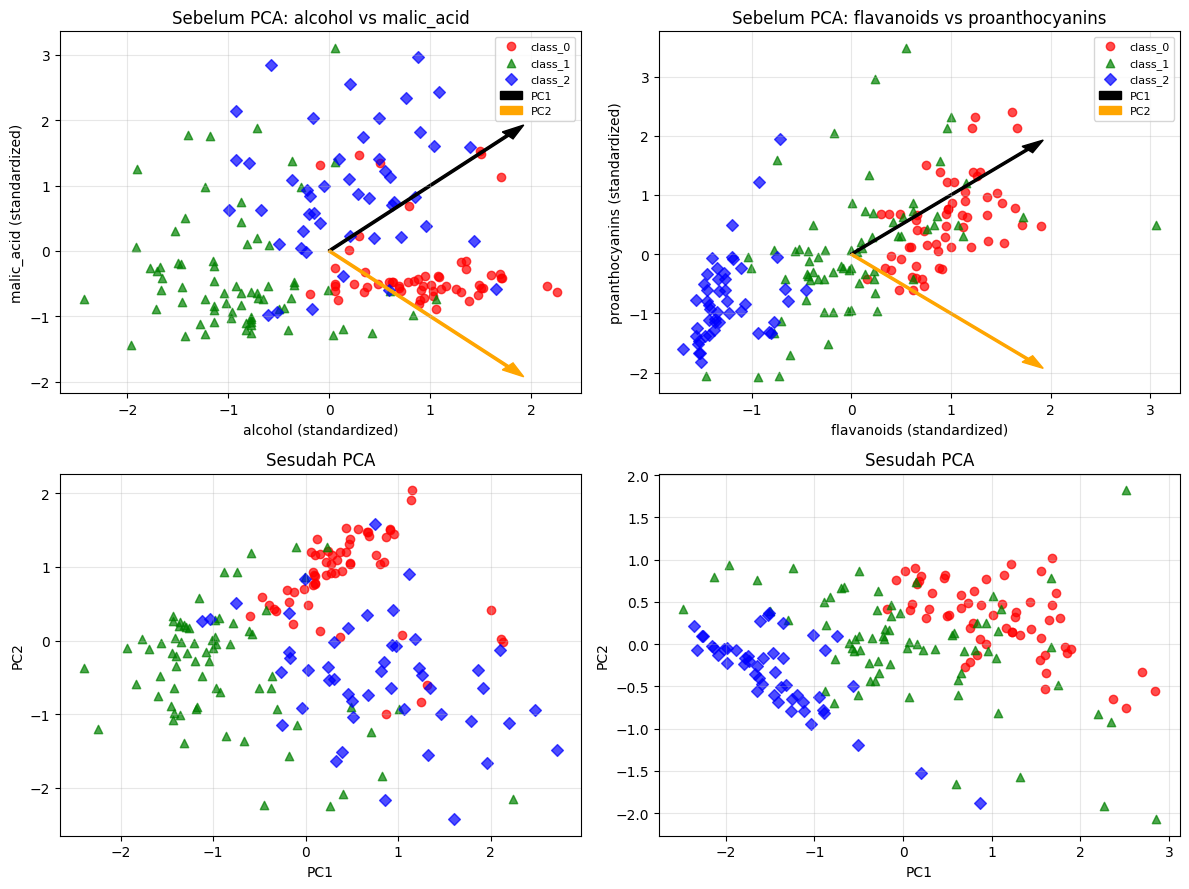

In [ ]:
# [Tambahan] Kode sendiri untuk Figure 3.4: dua fitur sebelum vs sesudah PCA
pairs = [("alcohol", "malic_acid"), ("flavanoids", "proanthocyanins")]
shapes = ["o", "^", "D"]; colors = ["r", "g", "b"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for col, (f1, f2) in enumerate(pairs):
    X2 = StandardScaler().fit_transform(df_wine[[f1, f2]])
    pca2 = PCA(n_components=2).fit(X2)
    Z2 = pca2.transform(X2)

    for i, (shape, color) in enumerate(zip(shapes, colors)):
        m = target_wine == i
        axes[0, col].scatter(X2[m, 0], X2[m, 1], c=color, marker=shape, alpha=0.7, label=wine.target_names[i])
        axes[1, col].scatter(Z2[m, 0], Z2[m, 1], c=color, marker=shape, alpha=0.7)

    # panah arah PC1 dan PC2 pada ruang fitur asli (atas)
    for j, c in enumerate(["black", "orange"]):
        v = pca2.components_[j] * 2.5
        axes[0, col].arrow(0, 0, v[0], v[1], color=c, width=0.03, head_width=0.15, label=f"PC{j+1}")
    axes[0, col].set_xlabel(f1 + " (standardized)"); axes[0, col].set_ylabel(f2 + " (standardized)")
    axes[0, col].set_title("Sebelum PCA: " + f1 + " vs " + f2); axes[0, col].legend(fontsize=8)
    axes[1, col].set_xlabel("PC1"); axes[1, col].set_ylabel("PC2")
    axes[1, col].set_title("Sesudah PCA")
    for r in (0, 1): axes[r, col].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretasi:** baris atas menunjukkan dua fitur terstandarisasi dan arah PC1/PC2 di atasnya. Baris bawah menunjukkan data yang sama setelah diputar ke sumbu PC. Perhatikan: buku menulis bahwa PCA "membantu memisahkan kelas lebih baik" pada gambar ini, tetapi dengan dua fitur PCA hanya merotasi data sehingga **keterpisahan kelas tidak bertambah** (kelas tetap tumpang tindih di kedua baris). Manfaat PCA terlihat pada data berdimensi tinggi. PCA hanya **merotasi** (dan memusatkan) data sehingga sumbu pertama menangkap variansi terbesar; jarak antartitik tidak berubah, yang berubah hanya sumbu pandangnya. Bila hanya 2 fitur, PCA tidak mengurangi dimensi, hanya mengubah sumbu. Reduksi dimensi sesungguhnya terjadi pada data berdimensi tinggi (13 → 2).

## 2. Maximizing Class Separability with LDA
**LDA (Linear Discriminant Analysis)** adalah teknik reduksi dimensi **supervised** yang berguna untuk klasifikasi. Berbeda dari PCA yang memaksimalkan variansi tanpa melihat label, LDA mencari sumbu yang **memaksimalkan keterpisahan antar kelas**.

### How to do it…
Dataset Wine yang sama. Jumlah komponen LDA maksimum = $\min(\text{n\_fitur},\ \text{n\_kelas} - 1)$, yaitu $\min(13, 2) = 2$ untuk Wine. Berbeda dari PCA, `fit_transform` LDA **membutuhkan `y`**.

In [ ]:
# [Dari buku] Pipeline LDA: scaling -> LDA 2 komponen
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X_wine, y_wine = wine.data, wine.target

lda_pipeline_wine = Pipeline([
    ("scaler", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis(n_components=2)),   # min(n_features, n_classes - 1) = 2
])
X_lda_wine = lda_pipeline_wine.fit_transform(X_wine, y_wine)
print("Bentuk:", X_wine.shape, "->", X_lda_wine.shape)

Bentuk: (178, 13) -> (178, 2)


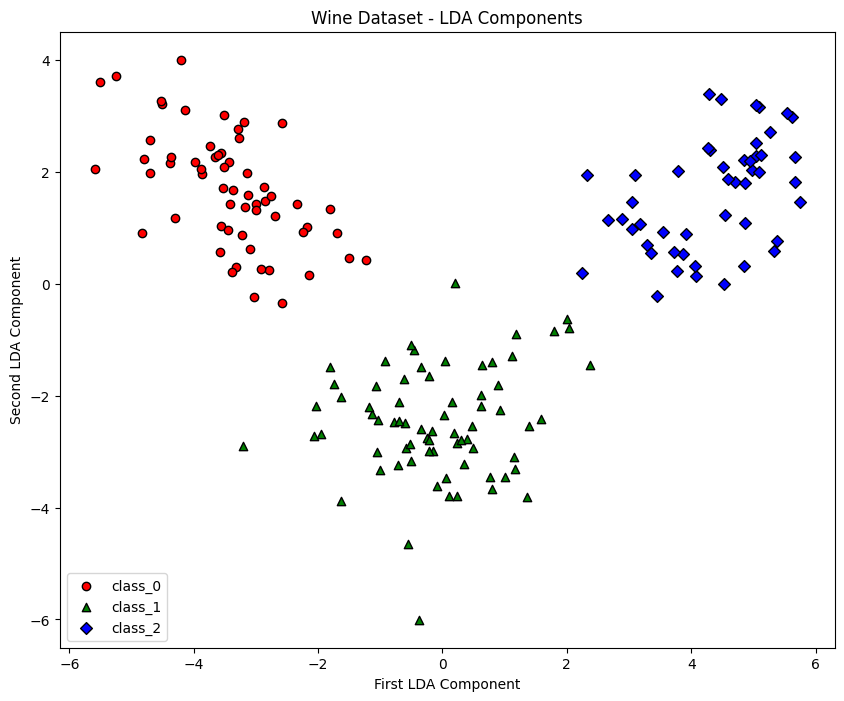

In [ ]:
# [Dari buku] Visualisasi LDA
plt.figure(figsize=(10, 8))
shapes = ["o", "^", "D"]
colors = ["r", "g", "b"]

for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(
        X_lda_wine[mask, 0], X_lda_wine[mask, 1],
        c=color, marker=shape, edgecolor="black", label=wine.target_names[i],
    )

plt.xlabel("First LDA Component")
plt.ylabel("Second LDA Component")
plt.title("Wine Dataset - LDA Components")
plt.legend()
plt.show()

**Interpretasi:** setelah LDA, ketiga kelas anggur membentuk kelompok yang jelas terpisah (Figure 3.5 di buku), lebih tegas daripada hasil PCA.

### How it works…
LDA mencari kombinasi linear fitur yang paling baik memisahkan dua atau lebih kelas. Tujuan utamanya:
- **Memaksimalkan keterpisahan kelas:** mencari sumbu yang membuat jarak **antar** kelas besar dan sebaran **dalam** tiap kelas kecil.
- **Reduksi dimensi:** memproyeksikan data ke ruang berdimensi rendah yang dibentuk *linear discriminants*.
- **Asumsi:** data tiap kelas berdistribusi **Gaussian** dengan **matriks kovarians yang sama** (kira-kira, tiap fitur punya variansi serupa, sebab itu data distandarisasi).

Secara formal, LDA memaksimalkan rasio sebaran antar-kelas terhadap sebaran dalam-kelas: $J(w) = \dfrac{w^\top S_B\, w}{w^\top S_W\, w}$, dengan $S_B$ = *between-class scatter* dan $S_W$ = *within-class scatter*.

## 3. Differences between PCA and LDA
| Aspek | PCA | LDA |
|---|---|---|
| **Jenis** | Unsupervised (tidak memakai label) | Supervised (memakai label) |
| **Tujuan** | Memaksimalkan variansi | Memaksimalkan keterpisahan kelas |
| **Output** | *Principal components* (ortogonal) | *Linear discriminants* |
| **Jumlah komponen maks.** | $\min(n_{sampel}, n_{fitur})$ | $\min(n_{fitur}, n_{kelas}-1)$ |
| **Pemakaian** | Analisis eksploratif, ekstraksi fitur tanpa label | Tugas klasifikasi |

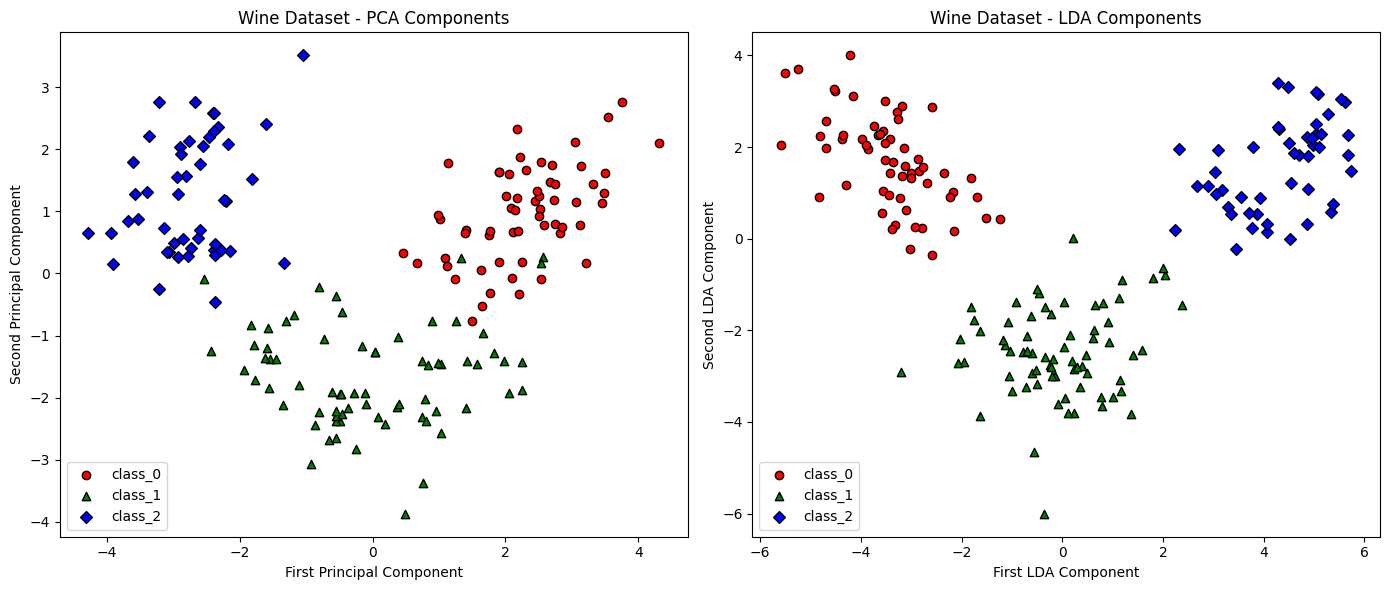

In [ ]:
# [Dari buku] PCA vs LDA berdampingan (memakai X_pca dan X_lda_wine dari sel sebelumnya)
plt.figure(figsize=(14, 6))
plt.subplot(121)
shapes = ["o", "^", "D"]
colors = ["r", "g", "b"]
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, marker=shape, edgecolor="black", label=wine.target_names[i])
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("Wine Dataset - PCA Components")
plt.legend()

plt.subplot(122)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1], c=color, marker=shape, edgecolor="black", label=wine.target_names[i])
plt.xlabel("First LDA Component")
plt.ylabel("Second LDA Component")
plt.title("Wine Dataset - LDA Components")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretasi:** keterpisahan kelas tampak sedikit lebih tegas pada LDA. Buku mencatat bahwa ini sebagian disebabkan LDA *supervised*, yaitu memakai label kelas saat mencari sumbu, sedangkan PCA tidak pernah melihat label. Pada data tertentu, tampilan keduanya bisa mirip.

In [ ]:
# [Tambahan] Bukti kuantitatif: akurasi klasifikasi dengan 2 komponen dari PCA vs LDA vs semua 13 fitur.
# Reduksi dimensi dimasukkan DI DALAM pipeline sehingga hanya dipelajari dari fold latih (tanpa data leakage).
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
candidates = {
    "13 fitur asli": Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "PCA (2 komponen)": Pipeline([("sc", StandardScaler()), ("pca", PCA(2)), ("clf", LogisticRegression(max_iter=1000))]),
    "LDA (2 komponen)": Pipeline([("sc", StandardScaler()), ("lda", LinearDiscriminantAnalysis(n_components=2)), ("clf", LogisticRegression(max_iter=1000))]),
}
rows = []
for name, pipe in candidates.items():
    s = cross_val_score(pipe, wine.data, wine.target, cv=cv)
    rows.append({"Representasi": name, "Akurasi CV (mean)": round(s.mean(), 4), "Std": round(s.std(), 4)})
display(pd.DataFrame(rows))

,Representasi,Akurasi CV (mean),Std
0,13 fitur asli,0.9830,0.0139
1,PCA (2 komponen),0.9717,0.0252
2,LDA (2 komponen),0.9943,0.0114


**Interpretasi:** tabel menunjukkan seberapa baik klasifikasi bila hanya memakai 2 dimensi hasil PCA atau LDA dibanding semua fitur. LDA umumnya mempertahankan informasi yang relevan untuk klasifikasi dengan hanya 2 dimensi, sedangkan PCA 2 komponen bisa lebih rendah karena memilih arah berdasarkan variansi, bukan berdasarkan kelas. Perhatikan bahwa reduksi dimensi dilakukan **di dalam** pipeline agar evaluasi tetap jujur.

## 4. t-SNE and Data Visualization
**t-SNE (t-Distributed Stochastic Neighbor Embedding)** adalah teknik reduksi dimensi **non-linear** untuk memvisualisasikan data berdimensi tinggi dalam 2D atau 3D. Sangat efektif menampakkan struktur, klaster, dan hubungan dalam data kompleks.

### Getting ready: dataset Digits
Dataset `load_digits` berisi gambar angka tulisan tangan 0–9 berukuran **8×8 piksel** (64 fitur, nilai 0–16), total 1.797 sampel. Dibentuk dari bitmap 32×32 yang dibagi menjadi blok 4×4 dan dihitung piksel menyala per blok.

> **Catatan koreksi:** buku menyebutnya "MNIST" dalam teks, tetapi `load_digits` bukan MNIST (MNIST berisi 70.000 gambar 28×28). Dataset ini adalah *UCI Optical Recognition of Handwritten Digits*.

In [ ]:
# [Dari buku] Muat dataset Digits
from sklearn.datasets import load_digits

digits = load_digits()
print("Bentuk data:", digits.data.shape, "| Jumlah kelas:", len(np.unique(digits.target)))

Bentuk data: (1797, 64) | Jumlah kelas: 10


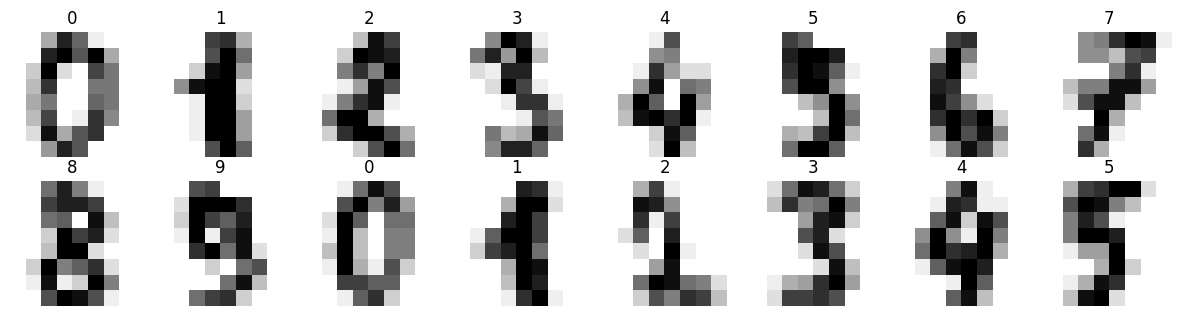

In [ ]:
# [Tambahan] Lihat beberapa contoh gambar (8x8 piksel)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, img, lab in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(str(lab)); ax.axis("off")
plt.tight_layout(); plt.show()

### How to do it…
Seperti sebelumnya, pipeline: scaling → t-SNE. `random_state=2024` dipakai karena t-SNE bersifat stokastik.

In [ ]:
# [Dari buku] Pipeline t-SNE
from sklearn.manifold import TSNE

tsne_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("tsne", TSNE(n_components=2, random_state=2024)),
])
X_tsne = tsne_pipeline.fit_transform(digits.data)
print("Bentuk:", digits.data.shape, "->", X_tsne.shape)

Bentuk: (1797, 64) -> (1797, 2)


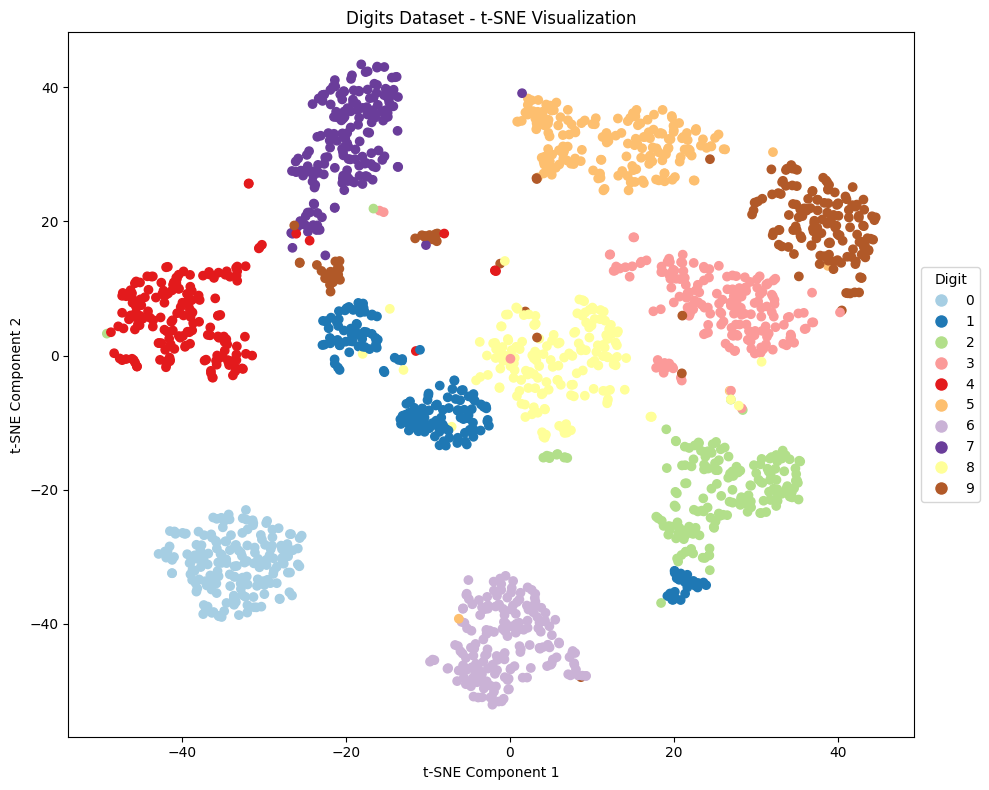

In [ ]:
# [Dari buku] Visualisasi t-SNE
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap="Paired", label=digits.target)
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("Digits Dataset - t-SNE Visualization")

legend_elements = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=plt.cm.Paired(i / 9), label=str(i), markersize=10)
    for i in range(10)
]
plt.legend(handles=legend_elements, title="Digit", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

**Interpretasi:** sepuluh kelas angka membentuk klaster yang cukup terpisah di 2D. Angka yang bentuknya mirip (misalnya 4, 7, 9) cenderung berdekatan, sedangkan angka yang unik seperti 0 membentuk klaster yang terpencil. Posisi pasti klaster dapat berbeda tiap versi library atau seed karena t-SNE stokastik, tetapi pola kedekatannya serupa.

### How it works…
t-SNE adalah teknik non-linear yang mengubah jarak Euclidean antar titik di ruang tinggi menjadi **probabilitas kemiripan**. Tahapannya:
1. **Kemiripan berpasangan (pairwise):** hitung kemiripan antar titik di ruang asli. Titik yang mirip diberi probabilitas tinggi, yang berbeda diberi probabilitas rendah.
2. **Pemetaan dimensi rendah:** cari representasi 2D/3D yang mempertahankan kemiripan itu sedekat mungkin (dioptimasi iteratif dengan meminimalkan *KL divergence* antara dua distribusi kemiripan).
3. **Pembentukan klaster:** hasilnya, titik mirip berkelompok dan titik tidak mirip berjauhan.

**Hal penting yang perlu diketahui tentang t-SNE (dari pengetahuan umum, bukan dari buku):**
- Hanya **jarak lokal** yang bermakna. Jarak antar klaster dan ukuran klaster di plot **tidak boleh diartikan secara kuantitatif**.
- Hasilnya dipengaruhi hyperparameter seperti `perplexity` dan bersifat stokastik.
- `TSNE` di scikit-learn hanya punya `fit_transform()`, **tidak ada `transform()`** untuk data baru. Karena itu t-SNE cocok untuk **visualisasi**, bukan sebagai langkah preprocessing sebelum model prediktif.

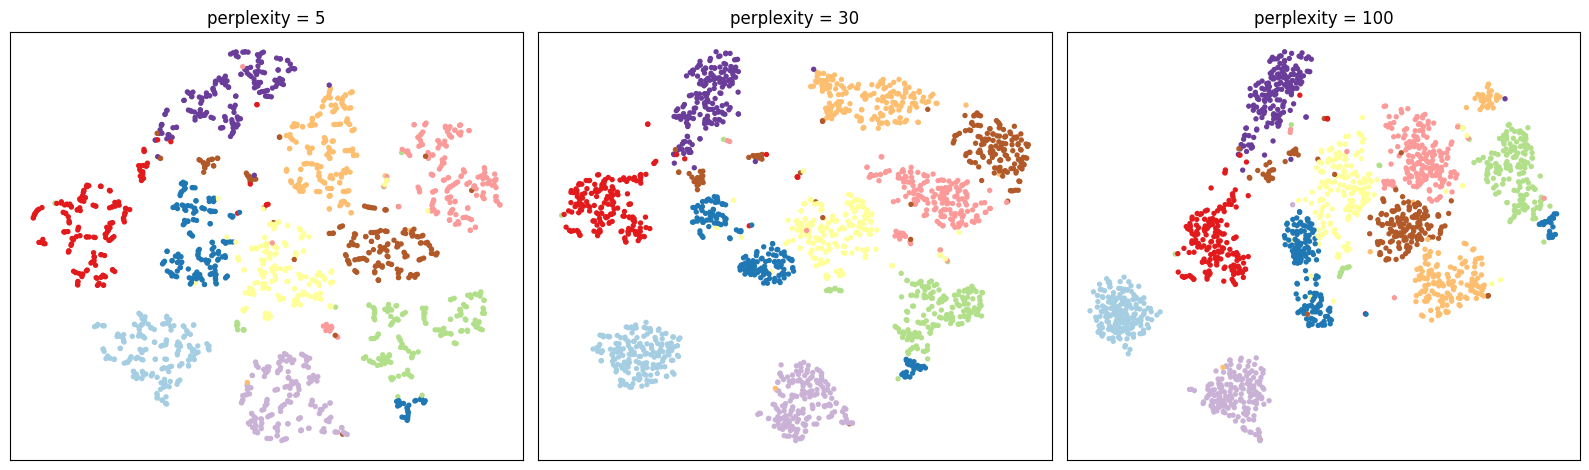

In [ ]:
# [Tambahan] Pengaruh perplexity pada hasil t-SNE (hyperparameter utama)
X_digits_scaled = StandardScaler().fit_transform(digits.data)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, perp in zip(axes, [5, 30, 100]):
    Z = TSNE(n_components=2, perplexity=perp, random_state=2024).fit_transform(X_digits_scaled)
    ax.scatter(Z[:, 0], Z[:, 1], c=digits.target, cmap="Paired", s=8)
    ax.set_title(f"perplexity = {perp}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Interpretasi:** `perplexity` mengatur seberapa banyak tetangga yang dipertimbangkan tiap titik. Nilai kecil menekankan struktur sangat lokal (klaster terpecah kecil-kecil), nilai besar menekankan struktur lebih global. Karena tidak ada nilai "benar" tunggal, praktik yang baik adalah mencoba beberapa nilai sebelum menarik kesimpulan.

## 5. Selecting the Right Technique
Memilih teknik yang tepat penting untuk mengelola data berdimensi tinggi. Teknik-teknik ini kadang bisa **dipakai bersamaan**.

### Pedoman pemilihan
| Pertanyaan | Panduan |
|---|---|
| **Supervised vs unsupervised?** | Data berlabel dan ingin memisahkan kelas → **LDA**. Tanpa label dan ingin menangkap variansi → **PCA**. t-SNE untuk visualisasi, berlabel maupun tidak. |
| **Variansi vs keterpisahan kelas?** | Pertahankan variansi → PCA. Tingkatkan keterpisahan kelas → LDA. Visualisasi hubungan/klaster kompleks → t-SNE. |
| **Ekstraksi fitur vs visualisasi?** | PCA dan LDA terutama untuk ekstraksi fitur; t-SNE khusus visualisasi. |
| **Efisiensi?** | PCA umumnya efisien untuk data besar. LDA menghitung rata-rata kelas dan matriks kovarians (kurang efisien untuk dimensi sangat tinggi atau banyak kelas). t-SNE berat pada data besar karena optimasi iteratif. |
| **Interpretabilitas?** | PCA: komponen adalah kombinasi linear fitur (kadang sulit ditafsirkan). LDA: lebih mudah ditafsirkan dalam hal pemisahan kelas. t-SNE: hasilnya visual, tanpa kontribusi fitur yang langsung dapat dibaca. |

### Table 3.1 — Perbandingan teknik (dari buku)
| Teknik | Tipe | Tujuan | Fitur utama | Kasus pemakaian terbaik |
|---|---|---|---|---|
| **PCA** | Unsupervised | Dimensionality reduction | Memaksimalkan variansi; kombinasi linear fitur | Analisis eksploratif, pengurangan *noise*, ekstraksi fitur |
| **LDA** | Supervised | Dimensionality reduction | Memaksimalkan keterpisahan kelas; *linear discriminants* | Klasifikasi yang membutuhkan pemisahan kelas |
| **t-SNE** | Unsupervised | Visualisasi | Pemetaan non-linear; menampakkan klaster; menjaga struktur lokal | Visualisasi data berdimensi tinggi, analisis eksploratif |

> Flowchart Figure 3.8 di buku berbentuk gambar; isi keputusannya sejalan dengan pedoman di atas.

### Langkah praktis memilih
1. Tentukan tujuan: meningkatkan performa model atau memvisualisasikan hubungan kompleks.
2. Pahami data: berlabel atau tidak, dan karakteristik dimensinya.
3. Nilai ukuran data dan sumber daya komputasi.
4. Bila ragu, coba beberapa teknik (misalnya **PCA lalu t-SNE**) dan bandingkan wawasan atau performanya.
5. Evaluasi efektivitas berdasarkan metrik model atau kejelasan visualisasi.

Waktu PCA(30) + t-SNE: 7.8 detik | varians tersisa dari PCA(30): 89.3%


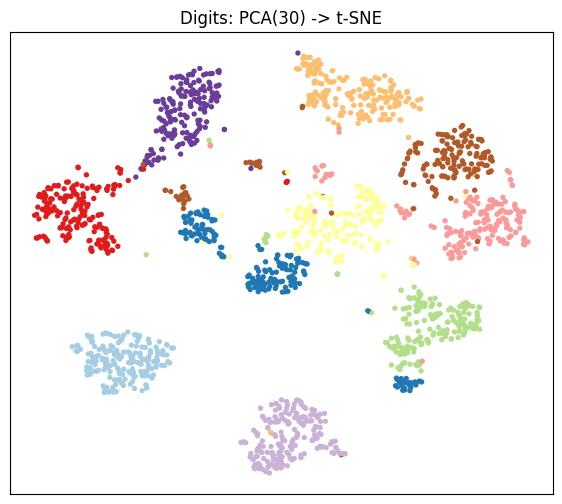

In [ ]:
# [Tambahan] Ilustrasi "PCA lalu t-SNE": PCA mengompres dulu (64 -> 30 dimensi), t-SNE memvisualisasikan.
# Cara ini lazim untuk mempercepat t-SNE pada data berdimensi sangat tinggi.
import time
t0 = time.time()
pca_tsne = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=30, random_state=2024)),
    ("tsne", TSNE(n_components=2, random_state=2024)),
])
Z = pca_tsne.fit_transform(digits.data)
print(f"Waktu PCA(30) + t-SNE: {time.time() - t0:.1f} detik | varians tersisa dari PCA(30): "
      f"{pca_tsne.named_steps['pca'].explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 6))
plt.scatter(Z[:, 0], Z[:, 1], c=digits.target, cmap="Paired", s=8)
plt.title("Digits: PCA(30) -> t-SNE"); plt.xticks([]); plt.yticks([]); plt.show()

## 6. Impact on Model Performance
Reduksi dimensi dapat sangat memengaruhi performa model: model lebih sederhana, pelatihan lebih cepat, dan risiko overfitting turun, tetapi akurasi bisa ikut terdampak. **Trade-off yang perlu dipertimbangkan:**

| Trade-off | Sisi positif | Sisi negatif / risiko |
|---|---|---|
| **Kompleksitas vs interpretabilitas** | Fitur lebih sedikit → model lebih sederhana dan mudah dijelaskan | Informasi penting bisa hilang |
| **Waktu pelatihan vs akurasi** | Dimensi rendah → pelatihan lebih cepat, sumber daya lebih hemat | Bila fitur penting terbuang, akurasi turun |
| **Overfitting vs generalisasi** | Menghilangkan *noise* dan fitur tak relevan → generalisasi lebih baik | Terlalu banyak dimensi dibuang → *underfitting* |

Penting: seberapa besar akurasi yang dikorbankan harus **dievaluasi** terhadap manfaat efisiensinya.

,Komponen PCA,Akurasi CV,Waktu fit total (dtk)
0,2,0.5431,0.14
1,5,0.8347,0.11
2,10,0.9015,0.13
3,20,0.9410,0.13
4,30,0.9410,0.19
5,64,0.9460,0.19


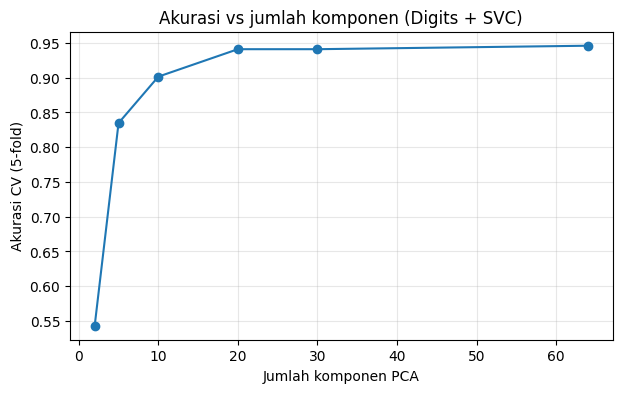

In [ ]:
# [Tambahan] Demonstrasi trade-off pada Digits: akurasi dan waktu fit vs jumlah komponen PCA
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate

rows = []
for k in [2, 5, 10, 20, 30, 64]:
    pipe = Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=k, random_state=2024)), ("clf", SVC())])
    r = cross_validate(pipe, digits.data, digits.target, cv=5)
    rows.append({"Komponen PCA": k, "Akurasi CV": round(r["test_score"].mean(), 4), "Waktu fit total (dtk)": round(r["fit_time"].sum(), 2)})
res = pd.DataFrame(rows); display(res)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(res["Komponen PCA"], res["Akurasi CV"], "o-")
ax.set_xlabel("Jumlah komponen PCA"); ax.set_ylabel("Akurasi CV (5-fold)")
ax.set_title("Akurasi vs jumlah komponen (Digits + SVC)"); ax.grid(True, alpha=0.3); plt.show()

**Interpretasi:** dengan sedikit komponen (misalnya 2) akurasi turun jauh karena banyak informasi hilang (*underfitting*). Seiring bertambahnya komponen, akurasi naik dan mulai mendatar. Titik di mana kurva mulai mendatar adalah kandidat jumlah komponen yang efisien: sudah cukup informatif tetapi jauh lebih ringkas daripada 64 fitur penuh. Kolom waktu menunjukkan sisi efisiensinya (hasil waktu bergantung pada mesin).

## Kesimpulan Chapter 3
- **Reduksi dimensi** menyederhanakan data, menghemat komputasi, mengurangi overfitting, dan memungkinkan visualisasi. Dibagi menjadi *feature selection* dan *feature extraction*.
- **PCA** (unsupervised) memproyeksikan data ke komponen ortogonal yang memaksimalkan variansi. Data harus distandarisasi dulu. Pada Wine, 2 komponen menjelaskan **55,41%** variansi.
- **LDA** (supervised) memaksimalkan keterpisahan kelas. Jumlah komponen maksimum $\min(n_{fitur}, n_{kelas}-1)$, dan asumsi Gaussian dengan kovarians sama.
- **t-SNE** (non-linear) unggul untuk visualisasi struktur lokal dan klaster, tetapi mahal secara komputasi, stokastik, dan tidak punya `transform()` untuk data baru.
- **Pilih teknik** berdasarkan tujuan (performa vs visualisasi), ketersediaan label, ukuran data, dan kebutuhan interpretabilitas. Teknik bisa dikombinasikan (PCA → t-SNE).
- Selalu evaluasi **trade-off**: kompleksitas vs interpretabilitas, waktu vs akurasi, overfitting vs underfitting.